# 07 beta rotation

Validation backtest for this trading module. The tape is synthetic and seeded, so the chart checks that the production rules fire and how the book compounds after 10 bps a side. It is not a live-edge claim.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
while ROOT.name and not (ROOT / "pipeline").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pipeline.research.validation.figures import draw_module, metrics_frame
from pipeline.research.validation.modules import run_module
from pipeline.research.validation.panel import synthetic_panel

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)


In [2]:
panel = synthetic_panel()
result = run_module('rotation', panel)
print(result.title)
for rule in result.rules:
    print("-", rule)
print()
print(result.note)
metrics_frame(result)


Module 12 — beta rotation canary
- Canary score uses the sector books (tech versus the broad book, and the defensive pair).
- When the score is positive, hold the tech book. Otherwise hold staples.
- The choice is refreshed every 5 sessions.
- Compared with staying in the broad book the whole time.

Synthetic tape, seeded. Paper costs of 10 bps a side. Not a live-edge claim. Sector books are the research canary paths, not the equity panel.


,days,total_return_pct,cagr_pct,sharpe,max_drawdown_pct,n_trades,win_rate_pct,avg_trade_pct
0,184,39.1,57.15,12.93,-0.35,184,77.72,0.18


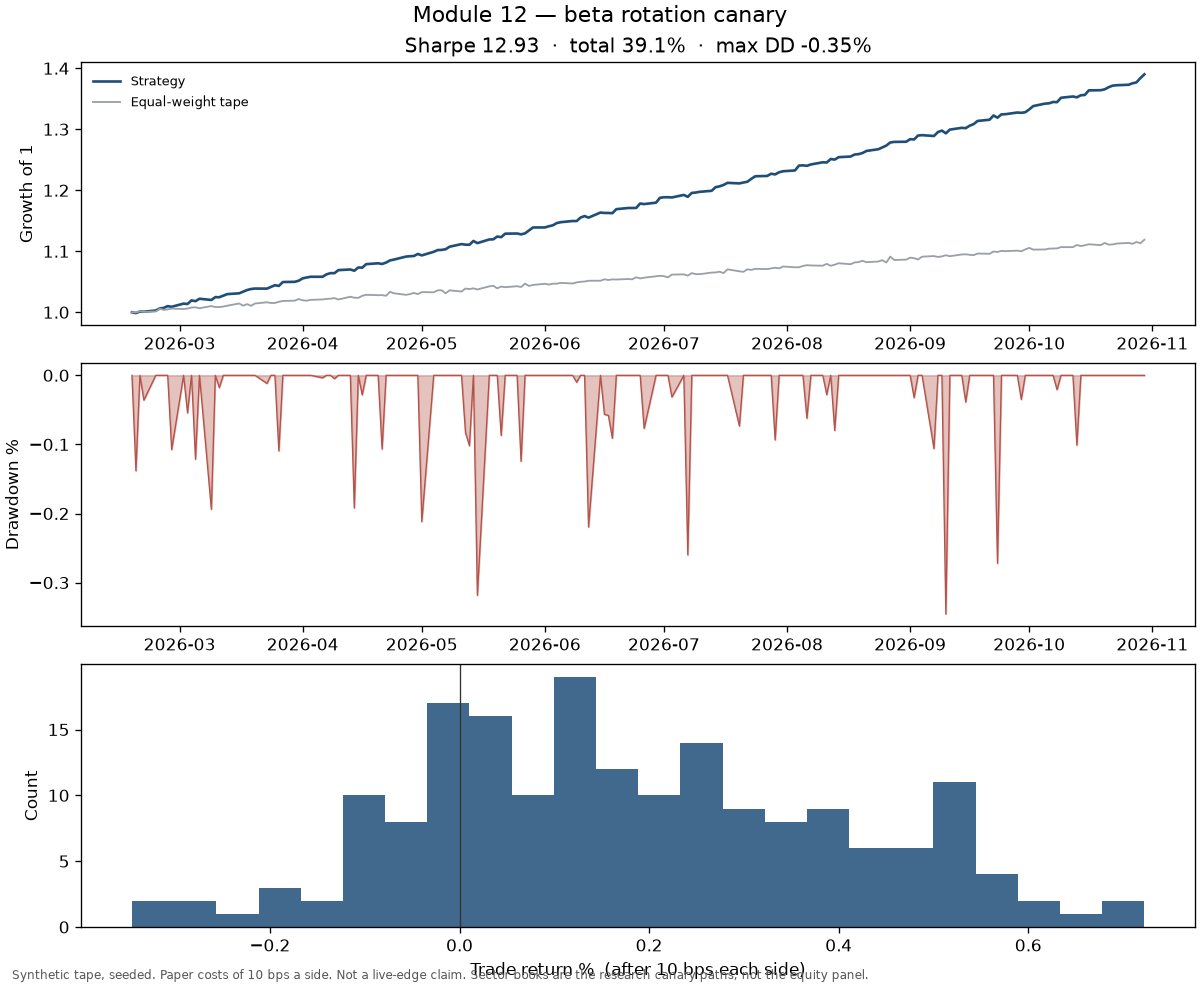

In [3]:
from IPython.display import Image, display

fig_dir = ROOT / "pipeline" / "research" / "notebooks" / "validation" / "figures"
fig_path = fig_dir / "07_beta_rotation.png"
fig = draw_module(result, fig_path)
plt.close(fig)
display(Image(filename=str(fig_path)))
